<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_33_QKV_weights_characteristics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt

import torch
from transformers import AutoModelForCausalLM

# Part_1:A dictionary of models

## Task_1:
- Create two dictionaries, one called models and one called params.
Both dictionaries have four keys corresponding to four GPT-2 sizes:
small, medium, large, and xl. The corresponding value in the
models dictionary are the models themselves. This will allow you to
access, e.g., GPT-2-large using models[’large’].
The second dictionary (params) has the same keys as above,
but each item is itself another dictionary, which contains the
following keys: the number of transformer layers (n_layers), the
embeddings dimensionality (n_emb), the number of heads (n_heads),
and the head dimensionality (head_dim). You can find these
parameters in the .config property of each model.
Create and print a table of model sizes and their parameters
as shown below

In [2]:
# a list of lists of model infos
model_ids = [
    #  name    label
    ['small' ,       'gpt2'],
    ['medium','gpt2-medium'],
    ['large' , 'gpt2-large'],
    ['xl'    ,    'gpt2-xl']
]


# load all models into a dictionary
models = {}
params = {}

for modinfo in model_ids:

  # load the model
  models[modinfo[0]] = AutoModelForCausalLM.from_pretrained(modinfo[1])

  # count key parameters
  params[modinfo[0]] = {}
  params[modinfo[0]]['n_layers'] = models[modinfo[0]].config.n_layer
  params[modinfo[0]]['n_emb']    = models[modinfo[0]].config.n_embd
  params[modinfo[0]]['n_heads']  = models[modinfo[0]].config.n_head
  params[modinfo[0]]['head_dim'] = models[modinfo[0]].config.n_embd // params[modinfo[0]]['n_heads']


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

... (10 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 6.43GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/580 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

In [3]:
print('"models" keys:\n',models.keys())
print('\n"params[''small'']" keys:\n',params['small'].keys())

"models" keys:
 dict_keys(['small', 'medium', 'large', 'xl'])

"params[small]" keys:
 dict_keys(['n_layers', 'n_emb', 'n_heads', 'head_dim'])


In [4]:
print('  Model  | Embed.dim | Layers | n heads | head.dim')
print('---------+-----------+--------+---------+---------')
for name in models.keys():
  print(f" {name:>6}  |    {params[name]['n_emb']:4}   |   {params[name]['n_layers']}   |    {params[name]['n_heads']}   |   {params[name]['head_dim']}")


  Model  | Embed.dim | Layers | n heads | head.dim
---------+-----------+--------+---------+---------
  small  |     768   |   12   |    12   |   64
 medium  |    1024   |   24   |    16   |   64
  large  |    1280   |   36   |    20   |   64
     xl  |    1600   |   48   |    25   |   64


In [7]:
models['small'].transformer.h[5].attn.c_attn.weight

Parameter containing:
tensor([[ 0.1861, -0.1976,  0.0349,  ..., -0.2001, -0.0534,  0.0589],
        [-0.2022, -0.0133,  0.3201,  ..., -0.0700,  0.0005,  0.1399],
        [ 0.0021, -0.0444,  0.1136,  ..., -0.1196,  0.0206, -0.0324],
        ...,
        [-0.4044,  0.2771,  0.4169,  ...,  0.0580, -0.0181,  0.0009],
        [-0.1154,  0.0917,  0.1954,  ..., -0.0979,  0.1045, -0.0064],
        [ 0.1259,  0.1661,  0.2583,  ...,  0.1098, -0.0762, -0.0539]],
       requires_grad=True)

## Task_2:
- Count and report the total number of trainable attention parameters
in each model. The number of trainable parameters is the number of
weights plus the number of bias terms. Hint: All layers have exactly
the same sized weights matrices.

In [8]:

# count total number of parameters in attention subblock

for modlist in model_ids:

  name = modlist[0]

  # isolate one layer
  block = models[name].transformer.h[5].attn

  # count the parameters in this layer
  params_per_layer = (
    block.c_attn.weight.numel()+
    block.c_attn.bias.numel() +
    block.c_proj.weight.numel() +
    block.c_proj.bias.numel()
  )

  # total params is weights times layers
  totparams = params_per_layer * params[name]['n_layers']

  # and print the info
  print(f'{totparams/1e6:5,.1f}M attention weights in GPT2-{name}')

 28.3M attention weights in GPT2-small
100.8M attention weights in GPT2-medium
236.1M attention weights in GPT2-large
491.8M attention weights in GPT2-xl


# Part 2: Distributions of attention weights in GPT-2-small

## Task_1:
- Extract the concatenated weights matrix from GPT-2-small from
layer index 6. The matrix is stored in the c_attn layer, and each
individual matrix has a dimensionality of the embeddings (variable
n_emb). Visualize the wide matrix as in Figure 6.1, and draw vertical
white dashed lines demarcating where the matrix is split into three.

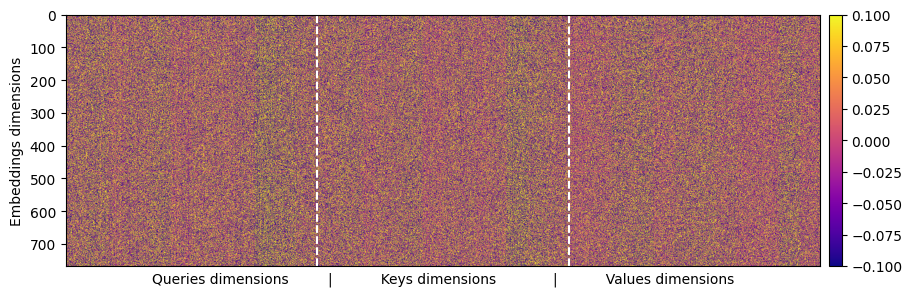

In [9]:

# in one layer for one model
whichmod = 'small'
layeri = 6

# extract the wide weights matrix for this layer
wide_weights = models[whichmod].transformer.h[layeri].attn.c_attn.weight.detach()

plt.figure(figsize=(10,3))
plt.imshow(wide_weights,vmin=-.1,vmax=.1,cmap='plasma')
plt.axvline(params[whichmod]['n_emb'],linestyle='--',color='w')
plt.axvline(2*params[whichmod]['n_emb'],linestyle='--',color='w')
plt.colorbar(pad=.01)

plt.gca().set(xticks=[],ylabel='Embeddings dimensions',
              xlabel='Queries dimensions         |           Keys dimensions             |           Values dimensions')


plt.tight_layout()
plt.show()

In [10]:
wide_weights.shape

torch.Size([768, 2304])

## Task_2:
- Split the wide matrix you just extracted into WQ, WK, and WV
matrices. Calculate histograms of the values in each matrix, and
visualize as line plots as in Figure 6.2.
Next, extract those histograms in a for-loop over all layers.
Use the same bin boundaries for all layers, and store the histogram
density values in a matrix of size 12 × N × 3, where 12 corresponds
to the number of transformer layers, N is the number of bins in your
histogram (I used 81), and 3 corresponds to the WQ, WK, and WV
matrices. Show the results in a heatmap as in Figure 6.3, in which
the rows (y-axis) are transformer layers, the columns (x-axis) are the
weights values, and color is the density (the height in the histogram).
Finally, extract the mean and standard deviation of each weights
matrix and show the results in scatter plots as in Figure 6.4.

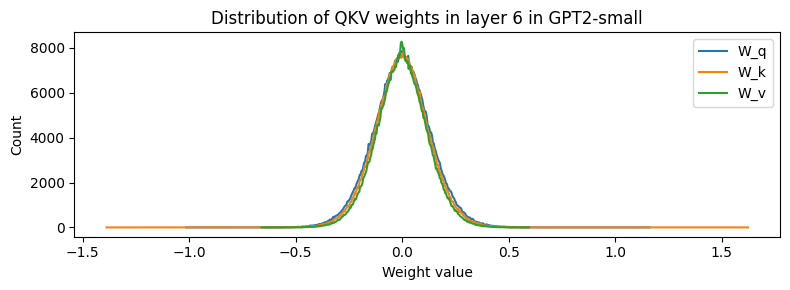

In [11]:
# split the Q, K, and V matrices
q,k,v = torch.split(wide_weights,params[whichmod]['n_emb'],dim=1)

# histograms of the three weights values
plt.figure(figsize=(8,3))
y,x = np.histogram(q.flatten(),bins='fd')
plt.plot(x[:-1],y,label='W_q')

y,x = np.histogram(k.flatten(),bins='fd')
plt.plot(x[:-1],y,label='W_k')

y,x = np.histogram(v.flatten(),bins='fd')
plt.plot(x[:-1],y,label='W_v')

plt.gca().set(xlabel='Weight value',ylabel='Count',
              title=f'Distribution of QKV weights in layer {layeri} in GPT2-{whichmod}')
plt.legend()

plt.tight_layout()
plt.show()

<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1717/2924777783.py:30: SyntaxWarning: invalid escape sequence '\m'
  axs[i].set(xlabel='Weight value',ylabel='Layer',title=f"$\mathbf{{W}}_{'QKV'[i]}$")


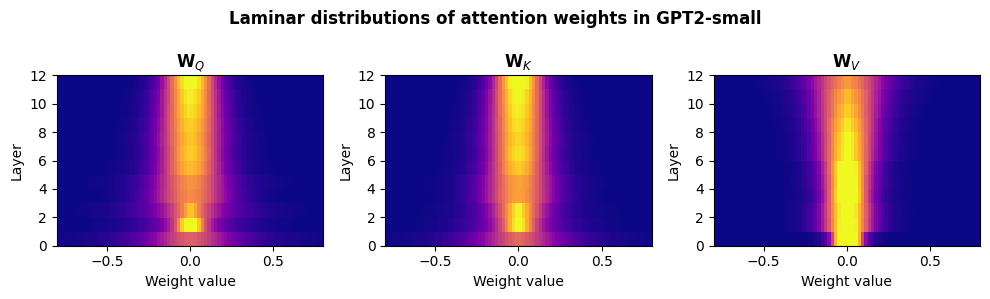

In [12]:
# common histogram boundaries
histedges = np.linspace(-.8,.8,81)

# initializations
distributions = np.zeros((params[whichmod]['n_layers'],len(histedges)-1,3))
distchars = np.zeros((params[whichmod]['n_layers'],2,3))

# loop over layers
for layeri in range(params[whichmod]['n_layers']):

  # split into matrices
  wideW = models[whichmod].transformer.h[layeri].attn.c_attn.weight.detach()
  q,k,v = torch.split(wideW,params[whichmod]['n_emb'],dim=1)

  # histograms
  distributions[layeri,:,0] = np.histogram(q.flatten(),bins=histedges,density=True)[0]
  distributions[layeri,:,1] = np.histogram(k.flatten(),bins=histedges,density=True)[0]
  distributions[layeri,:,2] = np.histogram(v.flatten(),bins=histedges,density=True)[0]

  # mean and std
  distchars[layeri,:,0] = np.array([q.mean(), q.std()])
  distchars[layeri,:,1] = np.array([k.mean(), k.std()])
  distchars[layeri,:,2] = np.array([v.mean(), v.std()])

# show the heatmaps
_,axs = plt.subplots(1,3,figsize=(10,3))
for i in range(3):
  axs[i].imshow(distributions[:,:,i],origin='lower',extent=[histedges[0],histedges[-1],0,params[whichmod]['n_layers']],
                aspect='auto',cmap=plt.cm.plasma,vmin=0,vmax=3.5)
  axs[i].set(xlabel='Weight value',ylabel='Layer',title=f"$\mathbf{{W}}_{'QKV'[i]}$")

plt.suptitle(f'Laminar distributions of attention weights in GPT2-{whichmod}',fontweight='bold')


plt.tight_layout()
plt.show()
